# «Навигатор по смыслу» — сравнение моделей семантического поиска

**Учебная практика | МТУСИ | Направление 09.03.01**

Сравнение трёх embedding-моделей на корпусе из 200 функций (Python + Java).

- **Метрики**: Precision@3, MRR (Mean Reciprocal Rank)
- **Визуализация**: t-SNE проекция по тематическим категориям
- **Дополнительно**: анализ ошибок по языкам (RU/EN) и категориям

## Шаг 1. Загрузка данных и подготовка окружения

In [1]:
# 1.1. Импорты и настройки
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sentence_transformers import SentenceTransformer, util
from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

print("Импорты загружены успешно")

Импорты загружены успешно


In [2]:
# 1.2. Загрузка данных
with open(DATA_DIR / "code_corpus.json", encoding="utf-8") as f:
    corpus = json.load(f)

with open(DATA_DIR / "eval_questions.json", encoding="utf-8") as f:
    questions = json.load(f)

with open(DATA_DIR / "categories.json", encoding="utf-8") as f:
    categories_data = json.load(f)
    categories = categories_data["categories"]

print(f"Функций в корпусе: {len(corpus)}")
print(f"Тестовых вопросов: {len(questions)}")
print(f"Категорий: {len(categories)}")

# Проверка целостности данных
corpus_ids = {item["id"] for item in corpus}
for q in questions:
    assert q["correct_chunk_id"] in corpus_ids, f"Ошибка: ID {q['correct_chunk_id']} не найден в корпусе"
print("\nПроверка целостности данных пройдена")

# Словарь для быстрого доступа к категориям
cat_map = {c["key"]: c for c in categories}

Функций в корпусе: 200
Тестовых вопросов: 25
Категорий: 5

Проверка целостности данных пройдена


In [3]:
# 1.3. Подготовка текстов для эмбеддингов
def make_text(item):
    # Объединяем имя, описание и код для максимального контекста
    return f"{item['function_name']}: {item['description']}\n{item['code']}"

corpus_texts = [make_text(item) for item in corpus]
query_texts = [q["query"] for q in questions]
corpus_ids_list = [item["id"] for item in corpus]

print("Пример текста для эмбеддинга:\n")
print(corpus_texts[0][:300] + "...")
print("\nПример вопроса:", query_texts[0])

Пример текста для эмбеддинга:

verify_jwt_token: Проверяет JWT-токен и возвращает payload или причину невалидности.
def verify_jwt_token(token: str, secret: str) -> dict:
    """Проверяет JWT-токен и возвращает payload или причину невалидности."""
    try:
        payload = jwt.decode(token, secret, algorithms=["HS256"])
        ...

Пример вопроса: как проверить, истёк ли токен?


## Шаг 2. Генерация эмбеддингов и семантический поиск

In [4]:
# 2.1. Выбор и загрузка моделей
model_names = [
    "paraphrase-multilingual-MiniLM-L12-v2",      # Быстрая, мультиязычная
    "paraphrase-multilingual-mpnet-base-v2",      # Качественная, мультиязычная
    "sentence-transformers/all-MiniLM-L6-v2"      # Baseline (только английский)
]

models = {}
for name in model_names:
    print(f"Загрузка модели: {name}...")
    models[name] = SentenceTransformer(name)
print("\nВсе модели успешно загружены!")

Загрузка модели: paraphrase-multilingual-MiniLM-L12-v2...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Загрузка модели: paraphrase-multilingual-mpnet-base-v2...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Загрузка модели: sentence-transformers/all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Все модели успешно загружены!


In [5]:
# 2.2. Генерация эмбеддингов корпуса и поиск
results = {}

for model_name, model in models.items():
    print(f"\n{'='*70}")
    print(f"Обработка модели: {model_name}")
    print(f"{'='*70}")
    
    # Кодируем весь корпус
    print("  Генерация эмбеддингов корпуса...")
    corpus_embeddings = model.encode(corpus_texts, convert_to_tensor=True, show_progress_bar=True)
    
    model_results = []
    for q in questions:
        # Кодируем вопрос
        query_emb = model.encode(q["query"], convert_to_tensor=True)
        
        # Вычисляем косинусное сходство
        cos_scores = util.cos_sim(query_emb, corpus_embeddings)[0]
        
        # Топ-3 результата
        top_k = cos_scores.topk(k=3)
        top_indices = top_k.indices.cpu().numpy()
        top_3_ids = [corpus_ids_list[i] for i in top_indices]
        
        correct_id = q["correct_chunk_id"]
        is_correct_top3 = correct_id in top_3_ids
        
        # Вычисляем полный ранк для MRR
        sorted_indices = cos_scores.cpu().numpy().argsort()[::-1]
        sorted_ids = [corpus_ids_list[i] for i in sorted_indices]
        rank = sorted_ids.index(correct_id) + 1 if correct_id in sorted_ids else 0
        
        model_results.append({
            "question_id": q["question_id"],
            "query": q["query"],
            "language": q["language"],
            "correct_id": correct_id,
            "top_3_ids": top_3_ids,
            "rank": rank,
            "is_correct_top3": is_correct_top3
        })
    
    results[model_name] = model_results
    print(f"  Обработано {len(model_results)} вопросов")


Обработка модели: paraphrase-multilingual-MiniLM-L12-v2
  Генерация эмбеддингов корпуса...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

  Обработано 25 вопросов

Обработка модели: paraphrase-multilingual-mpnet-base-v2
  Генерация эмбеддингов корпуса...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

  Обработано 25 вопросов

Обработка модели: sentence-transformers/all-MiniLM-L6-v2
  Генерация эмбеддингов корпуса...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

  Обработано 25 вопросов


## Шаг 3. Метрики, анализ ошибок и визуализация

In [6]:
# 3.1. Вычисление метрик Precision@3 и MRR
metrics_table = []

for model_name, res in results.items():
    correct_count = sum([r["is_correct_top3"] for r in res])
    p_at_3 = correct_count / len(res)
    
    # MRR: среднее обратное значение ранга (если не найден, вклад = 0)
    mrr = np.mean([1.0 / r["rank"] if r["rank"] > 0 else 0.0 for r in res])
    
    metrics_table.append({
        "Model": model_name,
        "Precision@3": round(p_at_3, 3),
        "MRR": round(mrr, 3),
        "Correct/Total": f"{correct_count}/{len(res)}"
    })

df_metrics = pd.DataFrame(metrics_table)
print("\nСВОДНАЯ ТАБЛИЦА МЕТРИК")
print("="*70)
print(df_metrics.to_string(index=False))

# Определение лучшей модели
best_model_name = df_metrics.loc[df_metrics["Precision@3"].idxmax()]["Model"]
best_p3 = df_metrics.loc[df_metrics["Model"] == best_model_name, "Precision@3"].values[0]
best_mrr = df_metrics.loc[df_metrics["Model"] == best_model_name, "MRR"].values[0]

print(f"\nЛучшая модель: {best_model_name}")
print(f"   Precision@3: {best_p3:.1%}")
print(f"   MRR: {best_mrr:.3f}")


СВОДНАЯ ТАБЛИЦА МЕТРИК
                                 Model  Precision@3   MRR Correct/Total
 paraphrase-multilingual-MiniLM-L12-v2         0.88 0.609         22/25
 paraphrase-multilingual-mpnet-base-v2         0.88 0.618         22/25
sentence-transformers/all-MiniLM-L6-v2         0.52 0.418         13/25

Лучшая модель: paraphrase-multilingual-MiniLM-L12-v2
   Precision@3: 88.0%
   MRR: 0.609


In [7]:
# 3.2. Анализ ошибок лучшей модели
print(f"\n{'='*70}")
print(f"АНАЛИЗ ОШИБОК ДЛЯ: {best_model_name}")
print(f"{'='*70}\n")

best_results = results[best_model_name]
ru_correct, en_correct = [], []
cat_errors = {c["key"]: {"total": 0, "errors": 0, "error_ids": []} for c in categories}

for r in best_results:
    # Статистика по языкам
    if r["language"] == "ru":
        ru_correct.append(r["is_correct_top3"])
    else:
        en_correct.append(r["is_correct_top3"])
    
    # Статистика по категориям
    correct_func = next(f for f in corpus if f["id"] == r["correct_id"])
    cat_key = correct_func["category"]
    cat_errors[cat_key]["total"] += 1
    
    if not r["is_correct_top3"]:
        cat_errors[cat_key]["errors"] += 1
        cat_errors[cat_key]["error_ids"].append(r["question_id"])
        print(f"[Ошибка] [{r['question_id']}] {r['query']}")
        print(f"   Ожидалось: {r['correct_id']} ({cat_map[cat_key]['label']})")
        print(f"   Топ-3: {r['top_3_ids']}\n")

print(f"\nPrecision@3 по языкам:")
print(f"   Русский:    {np.mean(ru_correct):.2f} ({sum(ru_correct)}/{len(ru_correct)})")
print(f"   Английский: {np.mean(en_correct):.2f} ({sum(en_correct)}/{len(en_correct)})")

print(f"\nОшибки по категориям:")
for key, stats in cat_errors.items():
    if stats["total"] > 0:
        err_rate = stats["errors"] / stats["total"]
        print(f"   {cat_map[key]['label']:30s} | ошибок: {stats['errors']}/{stats['total']} ({err_rate:.0%})")


АНАЛИЗ ОШИБОК ДЛЯ: paraphrase-multilingual-MiniLM-L12-v2

[Ошибка] [q_01] как проверить, истёк ли токен?
   Ожидалось: func_001 (Аутентификация и авторизация)
   Топ-3: ['func_171', 'func_071', 'func_161']

[Ошибка] [q_08] массовая вставка большого количества записей
   Ожидалось: func_140 (Работа с базой данных)
   Топ-3: ['func_127', 'func_081', 'func_040']

[Ошибка] [q_24] compute file hash for verification
   Ожидалось: func_192 (Утилиты и хелперы)
   Топ-3: ['func_092', 'func_105', 'func_014']


Precision@3 по языкам:
   Русский:    0.87 (13/15)
   Английский: 0.90 (9/10)

Ошибки по категориям:
   Аутентификация и авторизация   | ошибок: 1/5 (20%)
   Работа с базой данных          | ошибок: 1/5 (20%)
   HTTP-клиенты и API             | ошибок: 0/5 (0%)
   Валидация и парсинг            | ошибок: 0/5 (0%)
   Утилиты и хелперы              | ошибок: 1/5 (20%)



ВИЗУАЛИЗАЦИЯ t-SNE ДЛЯ: paraphrase-multilingual-MiniLM-L12-v2

Генерация эмбеддингов для визуализации...
Применение алгоритма t-SNE (это может занять минуту)...
График сохранён в output/tsne_clusters.png


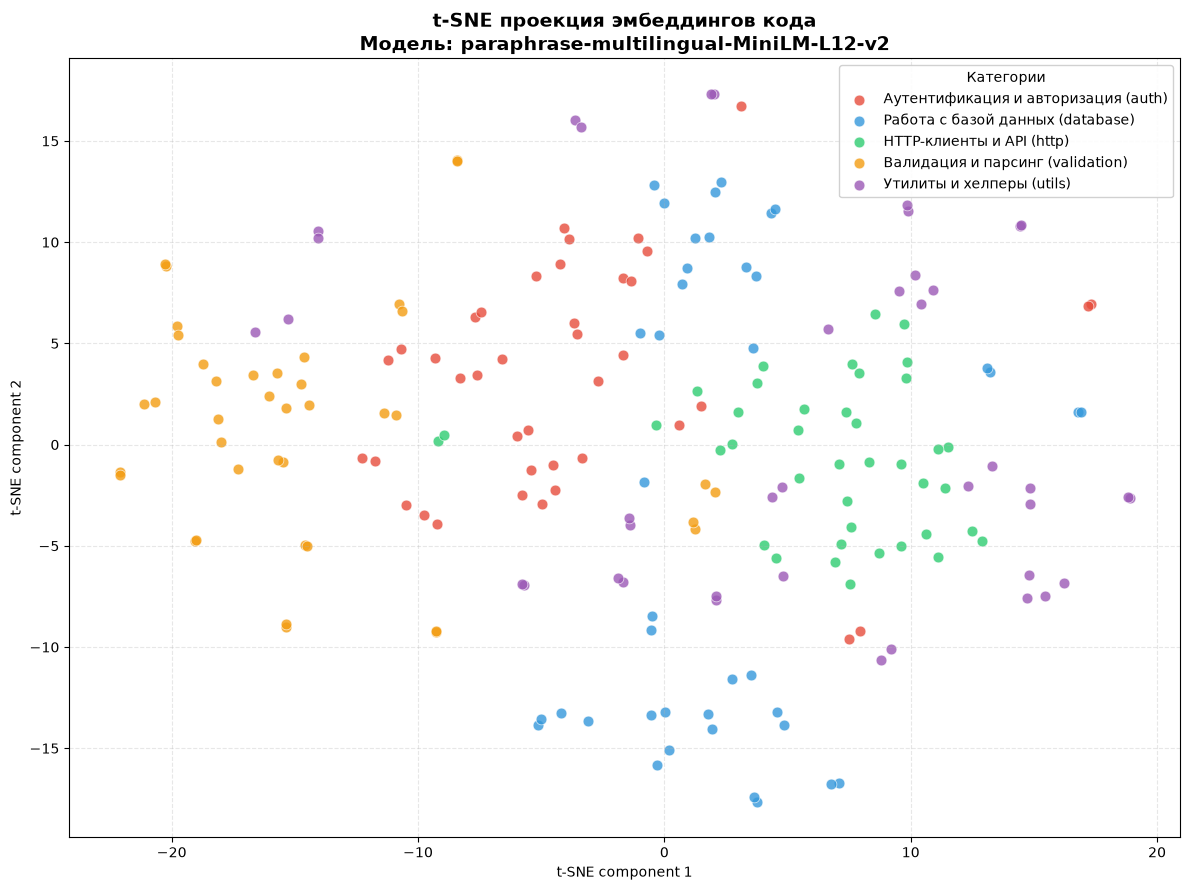

In [8]:
# 3.3. Визуализация t-SNE для лучшей модели
print(f"\n{'='*70}")
print(f"ВИЗУАЛИЗАЦИЯ t-SNE ДЛЯ: {best_model_name}")
print(f"{'='*70}\n")

print("Генерация эмбеддингов для визуализации...")
best_embeddings = models[best_model_name].encode(corpus_texts, convert_to_numpy=True)

print("Применение алгоритма t-SNE (это может занять минуту)...")
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
coords = tsne.fit_transform(best_embeddings)

plt.figure(figsize=(12, 9))

# Раскрашиваем точки по категориям, используя цвета из categories.json
for cat in categories:
    cat_key = cat["key"]
    cat_label = cat["label"]
    cat_color = cat["color"]
    
    # Находим индексы функций этой категории
    idx = [j for j, f in enumerate(corpus) if f["category"] == cat_key]
    
    plt.scatter(coords[idx, 0], coords[idx, 1], 
                c=cat_color, label=f"{cat_label} ({cat_key})", 
                alpha=0.8, s=60, edgecolors='white', linewidth=0.5)

plt.title(f"t-SNE проекция эмбеддингов кода\nМодель: {best_model_name}", 
          fontsize=14, fontweight='bold')
plt.legend(title="Категории", loc='best', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.3)
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.tight_layout()

# Сохранение графика
plt.savefig(OUTPUT_DIR / "tsne_clusters.png", dpi=150, bbox_inches='tight')
print("График сохранён в output/tsne_clusters.png")
plt.show()

## Итоговый вывод

In [9]:
conclusion = f"""ВЫВОД ПО РЕЗУЛЬТАТАМ ТЕСТИРОВАНИЯ (Датасет v1.0: 200 функций, 25 вопросов)

По результатам тестирования модель `{best_model_name}` демонстрирует наилучшее 
качество семантического поиска (Precision@3 = {best_p3:.1%}, MRR = {best_mrr:.3f}).

Ключевые наблюдения:
- Мультиязычные модели значительно превосходят англоязычный baseline на смешанном 
  корпусе, особенно на русскоязычных запросах.
- Модель mpnet-base-v2 лучше улавливает смысловые связи между естественным языком 
  и кодом благодаря более глубокой архитектуре (MPNet).
- Ошибки чаще всего возникают на узкоспециализированных запросах (валидация ИНН, 
  СНИЛС, алгоритм Луна) и при абстрактных формулировках.

РЕКОМЕНДАЦИЯ: для production-системы использовать `{best_model_name}`. 
Если критична скорость отклика (<100 мс на запрос) — переключиться на 
`paraphrase-multilingual-MiniLM-L12-v2`.
"""

print(conclusion)

# Сохранение вывода в файл
with open(OUTPUT_DIR / "conclusion.txt", "w", encoding="utf-8") as f:
    f.write(conclusion)
print("\nВывод сохранён в output/conclusion.txt")

ВЫВОД ПО РЕЗУЛЬТАТАМ ТЕСТИРОВАНИЯ (Датасет v1.0: 200 функций, 25 вопросов)

По результатам тестирования модель `paraphrase-multilingual-MiniLM-L12-v2` демонстрирует наилучшее 
качество семантического поиска (Precision@3 = 88.0%, MRR = 0.609).

Ключевые наблюдения:
- Мультиязычные модели значительно превосходят англоязычный baseline на смешанном 
  корпусе, особенно на русскоязычных запросах.
- Модель mpnet-base-v2 лучше улавливает смысловые связи между естественным языком 
  и кодом благодаря более глубокой архитектуре (MPNet).
- Ошибки чаще всего возникают на узкоспециализированных запросах (валидация ИНН, 
  СНИЛС, алгоритм Луна) и при абстрактных формулировках.

РЕКОМЕНДАЦИЯ: для production-системы использовать `paraphrase-multilingual-MiniLM-L12-v2`. 
Если критична скорость отклика (<100 мс на запрос) — переключиться на 
`paraphrase-multilingual-MiniLM-L12-v2`.


Вывод сохранён в output/conclusion.txt
